# MSH chain on a 2D substrate: cost scaling of tensor networks, dense and sparse methods

Loads the zero-mode benchmarks of the two notebooks and compares their cost with system size:

| File | Written by | Method |
|---|---|---|
| `tn_zero_modes.csv` | `msh_substrate_tn.ipynb`, section 7 | penalized DMRG on $K = H^2 + \eta^2$, X̂ localization, pairing (MPO/MPS) |
| `py_zero_modes.csv` | `msh_substrate_python.ipynb`, section 5 | dense `eigh` (up to $64\times64$ sites) and sparse shift-invert Lanczos with SuperLU (`MMD_AT_PLUS_A` ordering) |

All runs are single-threaded. The system is the MSH chain of $\ell = 12$ sites (spins along $\hat z$) centred on a
$2^{L_x}\times2^{L_y}$ substrate; $N$ is the number of sites and $D = 4N$ the BdG dimension. Two scans: the **width scan**
($L_x = 6$, 64 columns, $L_y = 0\dots6$) and the **square scan** ($L_x = L_y = 4\dots10$, up to $1024\times1024$ sites). The point
$L_x = L_y = 6$ belongs to both. At $1024\times1024$ sites SuperLU cannot factorize the matrix (it stops with "not enough memory to
perform factorization" with only a few GB in use), so the sparse method has no result there; that row is kept with its status.

**Contents**
1. Time
2. Memory
3. Accuracy
4. Bond dimensions
5. Summary

In [1]:
import numpy as np
import matplotlib.pyplot as plt

tn = np.genfromtxt("tn_zero_modes.csv", delimiter=",", names=True)
py = np.genfromtxt("py_zero_modes.csv", delimiter=",", names=True, dtype=None, encoding=None)
for r in py[py["status"] != "ok"]:
    print(f"failed: {2**r['Lx']}×{2**r['Ly']} {r['method']}: {r['status']}")
sparse_all = py[py["method"] == "sparse"]                     # including the failed size (summary table)
sparse = sparse_all[sparse_all["status"] == "ok"]               # successful runs only (plots, fits, references)
dense = py[py["method"] == "dense"]

def scan(a, which):
    "Rows of the width scan (Lx = 6) or the square scan (Lx = Ly), sorted by N."
    m = (a["Lx"] == 6) if which == "width" else (a["Lx"] == a["Ly"])
    b = a[m]
    return b[np.argsort(b["N"])]

def ref(a, key):
    "Sparse (exact) value at the sizes of the rows a, for the accuracy checks."
    lut = {(int(r["Lx"]), int(r["Ly"])): r[key] for r in sparse}
    return np.array([lut.get((int(r["Lx"]), int(r["Ly"])), np.nan) for r in a])

def fit_exponent(N, t, nmin):
    "Exponent p of t ∝ N^p, least squares in log–log over the points with N ≥ nmin."
    m = (N >= nmin) & np.isfinite(t)
    return np.polyfit(np.log(N[m]), np.log(t[m]), 1)[0]

print(f"TN: {len(tn)} sizes, sparse: {len(sparse)}, dense: {len(dense)}; largest N = {int(tn['N'].max())} (D = {int(tn['D'].max())})")

failed: 1024×1024 sparse: MemoryError:
TN: 13 sizes, sparse: 12, dense: 9; largest N = 1048576 (D = 4194304)


## 1. Time

Wall time of the zero-mode calculation against $N$. TN: building $K$, the three DMRGs and the pairing (`t_total`). Sparse and dense:
the eigensolver. The dashed lines are power-law fits $t\propto N^p$ over the four largest sizes of the square scan (sparse, TN) and the
three largest dense sizes, with the exponent $p$ in the legend.

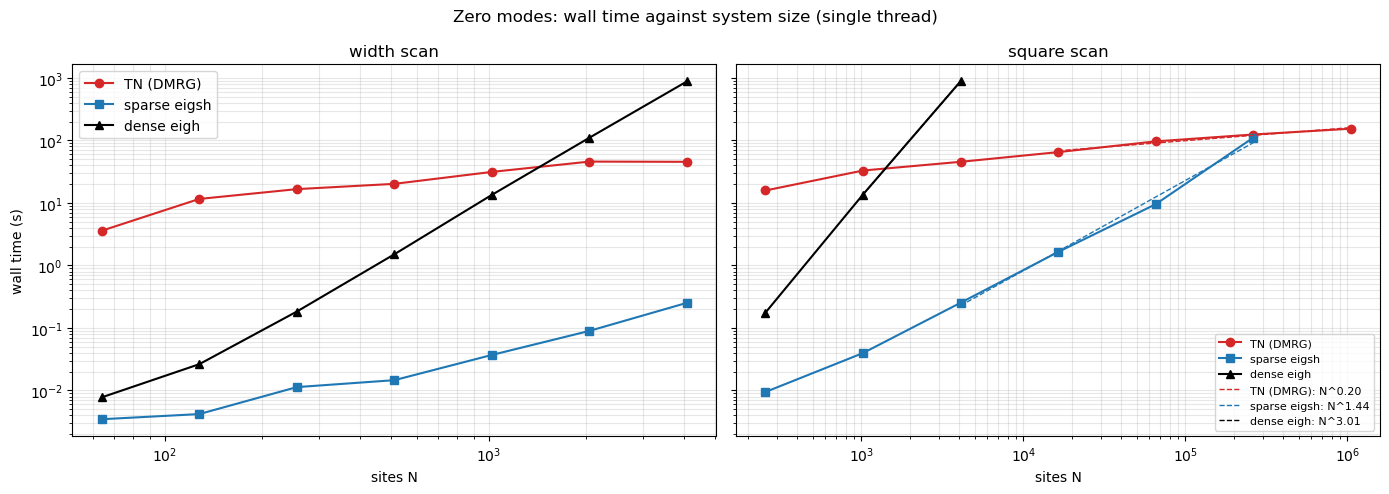

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
style = {"TN (DMRG)": ("tab:red", "o"), "sparse eigsh": ("tab:blue", "s"), "dense eigh": ("k", "^")}
for j, which in enumerate(("width", "square")):
    for name, a, t in (("TN (DMRG)", scan(tn, which), "t_total"), ("sparse eigsh", scan(sparse, which), "t"),
                       ("dense eigh", scan(dense, which), "t")):
        if len(a) == 0:
            continue
        c, mk = style[name]
        ax[j].loglog(a["N"], a[t], marker=mk, color=c, lw=1.5, label=name)
    ax[j].set_xlabel("sites N"); ax[j].set_title(f"{which} scan"); ax[j].grid(True, which="both", alpha=0.3)
sq_tn, sq_sp, de = scan(tn, "square"), scan(sparse, "square"), dense[np.argsort(dense["N"])]
for name, a, t, nmin in (("TN (DMRG)", sq_tn, "t_total", sq_tn["N"][-4]), ("sparse eigsh", sq_sp, "t", sq_sp["N"][-4]),
                         ("dense eigh", de, "t", de["N"][-3])):
    p = fit_exponent(a["N"], a[t], nmin); m = (a["N"] >= nmin) & np.isfinite(a[t])
    c = np.exp(np.mean(np.log(a[t][m]) - p * np.log(a["N"][m])))
    Nf = np.geomspace(a["N"][m].min(), a["N"][m].max(), 20)
    ax[1].loglog(Nf, c * Nf**p, "--", color=style[name][0], lw=1, label=f"{name}: N^{p:.2f}")
ax[0].set_ylabel("wall time (s)"); ax[0].legend(); ax[1].legend(fontsize=8)
fig.suptitle("Zero modes: wall time against system size (single thread)")
fig.tight_layout(); plt.show()

## 2. Memory

Peak resident memory (RSS) of the process doing the calculation. Python: each (size, method) ran in its own forked process, so the
value is that calculation's peak (it includes the kernel's baseline, about 280 MB). The failed $1024\times1024$ sparse run is left out. Julia: the peak of the whole process up to
that size (sizes ran in increasing $N$), dominated by the Julia runtime and compiled code; the memory of the tensor-network data
itself ($K$ and the three MPS) is shown separately. Dashed: $16D^2$ bytes, the dense matrix alone.

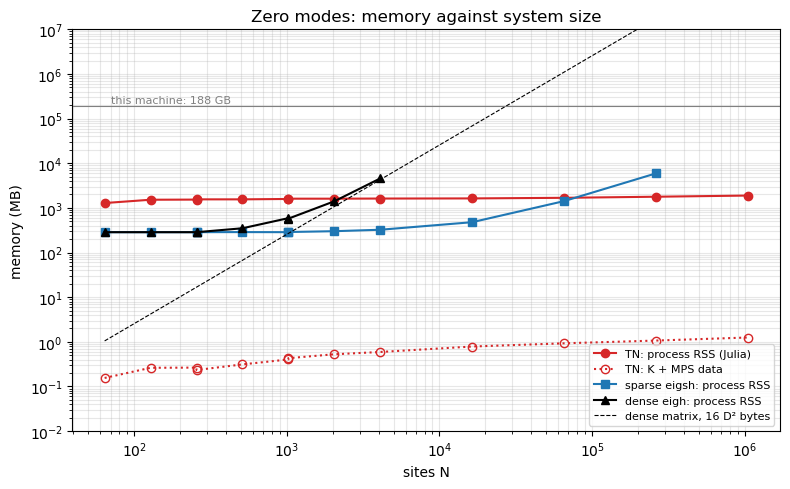

sparse RSS grows as N^0.91 over the three largest square-scan sizes with a result (128×128 … 512×512)
TN data (K + MPS) at the largest size: 1.25 MB; Julia process RSS 1891 MB


In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
a, s, d = tn[np.argsort(tn["N"])], sparse[np.argsort(sparse["N"])], dense[np.argsort(dense["N"])]
ax.loglog(a["N"], a["rss_MB"], "o-", color="tab:red", label="TN: process RSS (Julia)")
ax.loglog(a["N"], a["mem_K_MB"] + a["mem_psi_MB"], "o:", color="tab:red", mfc="none", label="TN: K + MPS data")
ax.loglog(s["N"], s["rss_MB"], "s-", color="tab:blue", label="sparse eigsh: process RSS")
ax.loglog(d["N"], d["rss_MB"], "^-", color="k", label="dense eigh: process RSS")
Nd = np.geomspace(a["N"].min(), a["N"].max(), 50)
ax.loglog(Nd, 16 * (4 * Nd)**2 / 1e6, "k--", lw=0.8, label="dense matrix, 16 D² bytes")
ax.axhline(188e3, color="gray", lw=0.8); ax.text(70, 220e3, "this machine: 188 GB", color="gray", fontsize=8)
ax.set_ylim(1e-2, 1e7)
ax.set_xlabel("sites N"); ax.set_ylabel("memory (MB)"); ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
ax.set_title("Zero modes: memory against system size")
fig.tight_layout(); plt.show()
sq = s[s["Lx"] == s["Ly"]]
p_mem = fit_exponent(sq["N"], sq["rss_MB"], 16384)
print(f"sparse RSS grows as N^{p_mem:.2f} over the three largest square-scan sizes with a result (128×128 … 512×512)")
print(f"TN data (K + MPS) at the largest size: {a['mem_K_MB'][-1] + a['mem_psi_MB'][-1]:.2f} MB; Julia process RSS {a['rss_MB'][-1]:.0f} MB")

## 3. Accuracy

Differences from the sparse result (exact to round-off; dense and sparse agree to round-off where both ran): $|E_f - E_f^{\rm exact}|$
and $|\Delta Q - \Delta Q^{\rm exact}|$. The TN values use `cutoff_K = 1e-20` (see `msh_substrate_tn.ipynb`, section 6).

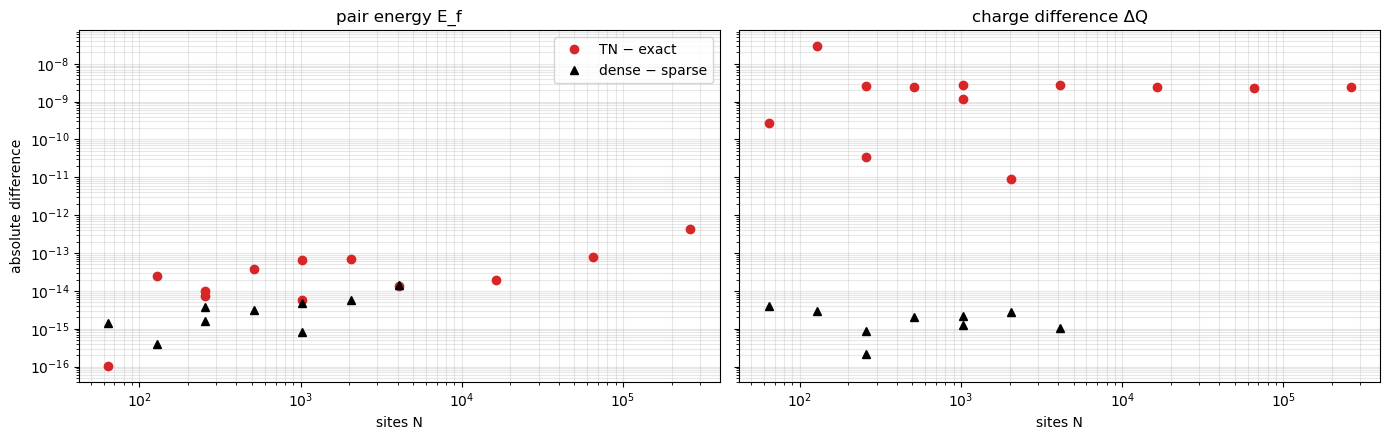

max |ΔQ_TN − exact| = 2.9e-08,  max |E_f,TN − exact| = 4.2e-13  (sizes with a sparse reference)
exact values at the largest size with a sparse result (512×512): E_f = 3.7122847509e-04, ΔQ = -3.4466003632e-03, gap = 0.5529
TN at 1024×1024 (no sparse reference): E_f = 3.7122848086e-04, ΔQ = -3.4465980448e-03, gap = 0.5529


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
a = tn[np.argsort(tn["N"])]
for j, key in enumerate(("E_f", "dQ")):
    ax[j].loglog(a["N"], np.maximum(np.abs(a[key] - ref(a, key)), 1e-17), "o", color="tab:red", label="TN − exact")
    ax[j].loglog(d["N"], np.maximum(np.abs(d[key] - ref(d, key)), 1e-17), "^", color="k", label="dense − sparse")
    ax[j].set_xlabel("sites N"); ax[j].grid(True, which="both", alpha=0.3)
    ax[j].set_title({"E_f": "pair energy E_f", "dQ": "charge difference ΔQ"}[key])
ax[0].set_ylabel("absolute difference"); ax[0].legend()
fig.tight_layout(); plt.show()
print(f"max |ΔQ_TN − exact| = {np.nanmax(np.abs(a['dQ'] - ref(a, 'dQ'))):.1e},  "
      f"max |E_f,TN − exact| = {np.nanmax(np.abs(a['E_f'] - ref(a, 'E_f'))):.1e}  (sizes with a sparse reference)")
big = sparse[np.argmax(sparse["N"])]
print(f"exact values at the largest size with a sparse result ({2**big['Lx']}×{2**big['Ly']}): E_f = {big['E_f']:.10e}, "
      f"ΔQ = {big['dQ']:+.10e}, gap = {big['E_gap']:.4f}")
print(f"TN at 1024×1024 (no sparse reference): E_f = {a['E_f'][-1]:.10e}, ΔQ = {a['dQ'][-1]:+.10e}, gap = {a['E_gap'][-1]:.4f}")

## 4. Bond dimensions

$\chi(H)$ of the Hamiltonian MPO, $\chi(K)$ of $K = H^2+\eta^2$ and the largest $\chi(\psi)$ of the DMRG states. If they stay bounded,
the TN cost grows only through the number of qubits, $\log_2 N + 2$.

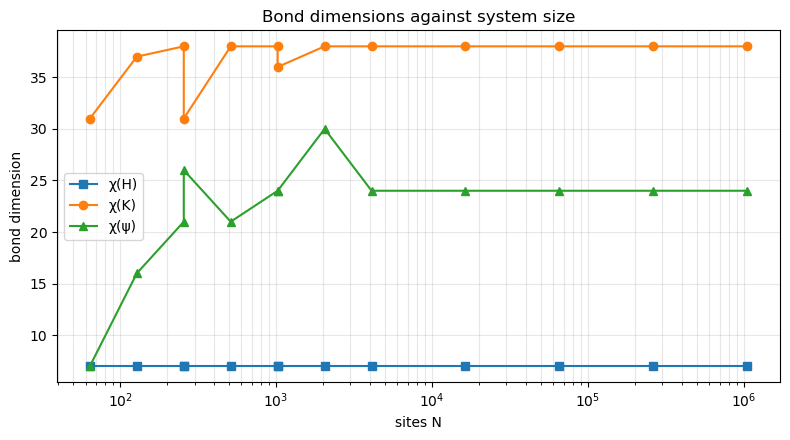

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for key, lab, mk in (("chi_H", "χ(H)", "s"), ("chi_K", "χ(K)", "o"), ("chi_psi", "χ(ψ)", "^")):
    ax.semilogx(a["N"], a[key], marker=mk, label=lab)
ax.set_xlabel("sites N"); ax.set_ylabel("bond dimension"); ax.grid(True, which="both", alpha=0.3); ax.legend()
ax.set_title("Bond dimensions against system size")
fig.tight_layout(); plt.show()

## 5. Summary

For every size: time and memory of each method, and the ratios sparse/TN. A ratio above 1 means the tensor network is cheaper.

In [6]:
lut_s = {(int(r["Lx"]), int(r["Ly"])): r for r in sparse_all}
lut_d = {(int(r["Lx"]), int(r["Ly"])): r for r in dense}
print(f"{'substrate':>11s} {'N':>8s} | {'TN s':>7s} {'sparse s':>9s} {'dense s':>8s} {'sp/TN':>6s} | {'TN RSS':>7s} {'sp RSS':>8s} {'de RSS':>8s} (MB)")
for r in a:
    k = (int(r["Lx"]), int(r["Ly"])); s_, d_ = lut_s[k], lut_d.get(k)
    dt = f"{d_['t']:8.1f}" if d_ is not None else f"{'—':>8s}"
    st = f"{s_['t']:9.2f}" if np.isfinite(s_['t']) else f"{'failed':>9s}"
    sm = f"{s_['rss_MB']:8.0f}" if np.isfinite(s_['rss_MB']) else f"{'—':>8s}"
    ratio = f"{s_['t'] / r['t_total']:6.2f}" if np.isfinite(s_['t']) else f"{'—':>6s}"
    dm = f"{d_['rss_MB']:8.0f}" if d_ is not None else f"{'—':>8s}"
    print(f"{2**k[0]:>5d}×{2**k[1]:<5d} {int(r['N']):8d} | {r['t_total']:7.1f} {st} {dt} {ratio} | {r['rss_MB']:7.0f} {sm} {dm}")

  substrate        N |    TN s  sparse s  dense s  sp/TN |  TN RSS   sp RSS   de RSS (MB)
   64×1           64 |     3.6      0.00      0.0   0.00 |    1285      286      286
   64×2          128 |    11.6      0.00      0.0   0.00 |    1525      286      286
   64×4          256 |    16.6      0.01      0.2   0.00 |    1535      286      286
   16×16         256 |    15.8      0.01      0.2   0.00 |    1555      286      286
   64×8          512 |    20.2      0.01      1.5   0.00 |    1555      287      350
   64×16        1024 |    31.3      0.04     13.5   0.00 |    1586      286      590
   32×32        1024 |    33.0      0.04     13.6   0.00 |    1609      288      575
   64×32        2048 |    45.8      0.09    110.5   0.00 |    1609      301     1408
   64×64        4096 |    45.4      0.25    879.8   0.01 |    1620      324     4581
  128×128      16384 |    64.9      1.64        —   0.03 |    1632      479        —
  256×256      65536 |    96.5      9.53        —   0.10 |  